# What drives the walking commands? MDN, DNa01, DNa02 and DNg13 on MaleCNS

Issue #50. Four descending neuron (DN) types carry walking commands from the brain to the leg circuits:
**MDN** (moonwalker, backward walking; Bidaye et al. 2014), the steering DNs **DNa01** and **DNa02**
(Rayshubskiy et al. 2025) and **DNg13** (Yang et al. 2024). flybrain's `brain.groups` already names
`backward_*` (MDN), `steer_*` (DNa02) and `forward_*` (DNg100).

What this notebook does:

1. **Wiring (no simulation).** For each of the eight cells' groups (four types × two sides), the strongest direct inputs
   and two-step inputs by summed synaptic weight, grouped by cell type and by superclass.
2. **Simulation.** Stimulates the top candidate inputs one at a time (and a few the literature names) and records which
   walking DNs fire, against a paired no-stimulus run on the same noise seeds.
3. **Controls.** For every candidate, a random set of the same number of cells from the same superclass.
4. **Wiring vs model, and literature.** Where the direct wiring predicts the simulated effect and where it doesn't, and
   how that compares with published moonwalker and steering circuits.

Run from a fresh install: `pip install flybrain matplotlib`, `flybrain download`, then run all cells (about 12 minutes on
a laptop CPU). Plots and CSVs go to `notebooks/walking_inputs/`. Sections and plot titles say **wiring** or **simulated**.

In [1]:
import csv, time, collections
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import spearmanr

import flybrain
from flybrain import FlyBrain
from flybrain.data import ensure_data

# outputs go next to this notebook, whether it is run from notebooks/ or from the repo root
HERE = next(p for p in (Path.cwd(), Path.cwd() / "notebooks") if (p / "walking_inputs.ipynb").exists())
OUT = HERE / "walking_inputs"
OUT.mkdir(exist_ok=True)

BATCH = 16          # flies (noise seeds) run side by side
WARM = 10           # 0.2 s with no stimulus before each trial
STEPS = 50          # 1.0 s stimulus window (dt = 20 ms)
AMOUNT = 1.0        # injected voltage per step into every stimulated cell (makes each fire every step, 50 Hz)
TOP_DIRECT = 3      # excitatory direct inputs per target group to test
TOP_INHIB = 1       # inhibitory direct inputs per target group to test
TOP_TWO = 2         # two-step-only inputs per target group to test

DATA = ensure_data()
brain = FlyBrain(data=DATA, batch=BATCH, device="auto", sensory_input=True)   # the default, stated explicitly: see "What the model leaves out"
ct = brain.cell_type.astype(str); sd = brain.side.astype(str); sc = brain.superclass.astype(str)
W = sparse.load_npz(DATA / "weights.npz").tocsr()     # rows = postsynaptic
print("flybrain", getattr(flybrain, "__version__", "?"), "| device", brain.device, "| neurons", brain.n, "| dt", brain.dt)
print("nonzero |weight| percentiles 50/90/99:", np.round(np.percentile(np.abs(W.data), [50, 90, 99]), 4))

Matplotlib is building the font cache; this may take a moment.


flybrain 0.1.1 | device cpu | neurons 166700 | dt 0.02


nonzero |weight| percentiles 50/90/99: [0.0024 0.0139 0.0642]


## The walking DNs

The four types the issue names, plus other walking-related DNs that are read out too: `DNg100` (flybrain's
`forward_*` group), `DNp09` (forward walking, Bidaye et al. 2020) and `DNb05`/`DNb06` (steering correlates in
Yang et al. 2024). MDN has two cells per side in MaleCNS, the others one.

In [2]:
TARGETS = ["MDN", "DNa01", "DNa02", "DNg13"]
READ = TARGETS + ["DNg100", "DNp09", "DNb05", "DNb06"]
def group(t, s):
    return brain.cells([t], side=s)
READ = [t for t in READ if len(group(t, "L")) and len(group(t, "R"))]
for t in READ:
    print(f"{t:7} L {group(t, 'L').tolist()}  R {group(t, 'R').tolist()}")
walking = np.concatenate([group(t, s) for t in READ for s in "LR"])
print("groups:", {k: v.tolist() for k, v in brain.groups.items() if k.split('_')[0] in ('forward', 'steer', 'backward')})

MDN     L [1196, 2194]  R [706, 1240]
DNa01   L [406]  R [704]
DNa02   L [131957]  R [332]
DNg13   L [993]  R [125880]
DNg100  L [36]  R [46]
DNp09   L [725]  R [1087]
DNb05   L [104]  R [52]
DNb06   L [823]  R [988]
groups: {'forward_L': [36], 'forward_R': [46], 'steer_L': [131957], 'steer_R': [332], 'backward_L': [1196, 2194], 'backward_R': [706, 1240]}


## Wiring: direct and two-step inputs

Direct input from a presynaptic cell type = summed weight of all its synapses onto the target group's cells (signed:
negative = inhibitory). Two-step input from cell k = Σ_j W[target, j] · W[j, k] over every intermediate j, also
signed (an inhibitory step flips the sign). Inputs are grouped by (cell type, side).

In [3]:
def by_type(vec, exclude=()):
    agg = collections.defaultdict(float)
    for j in np.flatnonzero(vec):
        if j in exclude:
            continue
        agg[(ct[j], sd[j])] += float(vec[j])
    return agg

direct, twostep, superclass = {}, {}, {}
for t in TARGETS:
    for s in "LR":
        post = group(t, s)
        w1 = np.asarray(W[post].sum(axis=0)).ravel()
        w2 = (sparse.csr_matrix(w1) @ W).toarray().ravel()
        direct[(t, s)] = by_type(w1)
        twostep[(t, s)] = by_type(w2, exclude=set(post))
        sup = collections.defaultdict(lambda: [0.0, 0.0])
        for j in np.flatnonzero(w1):
            sup[sc[j]][0 if w1[j] > 0 else 1] += float(w1[j])
        superclass[(t, s)] = sup

rows = []
for (t, s), agg in direct.items():
    for k, ((pt, ps), v) in enumerate(sorted(agg.items(), key=lambda x: -abs(x[1]))[:15], 1):
        rows.append(dict(target=t, side=s, kind="direct", rank=k, input_type=pt, input_side=ps, weight=round(v, 5)))
    for k, ((pt, ps), v) in enumerate(sorted(twostep[(t, s)].items(), key=lambda x: -abs(x[1]))[:15], 1):
        rows.append(dict(target=t, side=s, kind="two-step", rank=k, input_type=pt, input_side=ps, weight=round(v, 6)))
with open(OUT / "wiring_inputs.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
for t in TARGETS:
    for s in "LR":
        d = [r for r in rows if r["target"] == t and r["side"] == s and r["kind"] == "direct"][:6]
        two = [r for r in rows if r["target"] == t and r["side"] == s and r["kind"] == "two-step"][:4]
        print(f"{t} {s}  direct: " + ", ".join(f"{r['input_type']} {r['input_side']} {r['weight']:+.3f}" for r in d))
        print(f"{' ' * len(t)}    two-step: " + ", ".join(f"{r['input_type']} {r['input_side']} {r['weight']:+.4f}" for r in two))

MDN L  direct: DNpe023 R +0.048, CB0095 R -0.044, CB0095 L -0.040, AN_multi_41 R -0.039, DNpe023 L +0.030, LAL160,LAL161 R +0.030
       two-step: LC9 R +0.0057, AN_multi_42 L -0.0049, AN_GNG_81 L -0.0042, DNge127 L +0.0040
MDN R  direct: DNpe023 L +0.044, AN_multi_41 L -0.044, CB0095 L -0.041, CB0095 R -0.028, DNpe023 R +0.027, LAL112 R -0.026
       two-step: AN_multi_45 R -0.0049, LAL171,LAL172 L +0.0041, DNge127 R +0.0041, AN_multi_42 R -0.0041
DNa01 L  direct: VES007 L +0.036, LT51 L -0.036, VES051,VES052 L -0.032, LAL124 R -0.025, CB4105 R +0.024, VES074 R +0.023
         two-step: LPC1 R +0.0049, LPLC4 R +0.0038, LLPC1 R +0.0032, Li05 L -0.0027
DNa01 R  direct: VES007 R +0.034, LT51 R -0.032, VES051,VES052 R -0.030, VES074 L +0.024, CB0433 R -0.024, DNge123 L -0.023
         two-step: LPC1 L +0.0043, LPLC4 L +0.0033, VES051,VES052 R -0.0024, LC4 L +0.0024
DNa02 L  direct: AN03A008 L +0.031, VES051,VES052 L -0.025, LAL028,LAL029 L +0.021, PS049 L -0.021, PS059 L -0.020, AN_IPS_GN

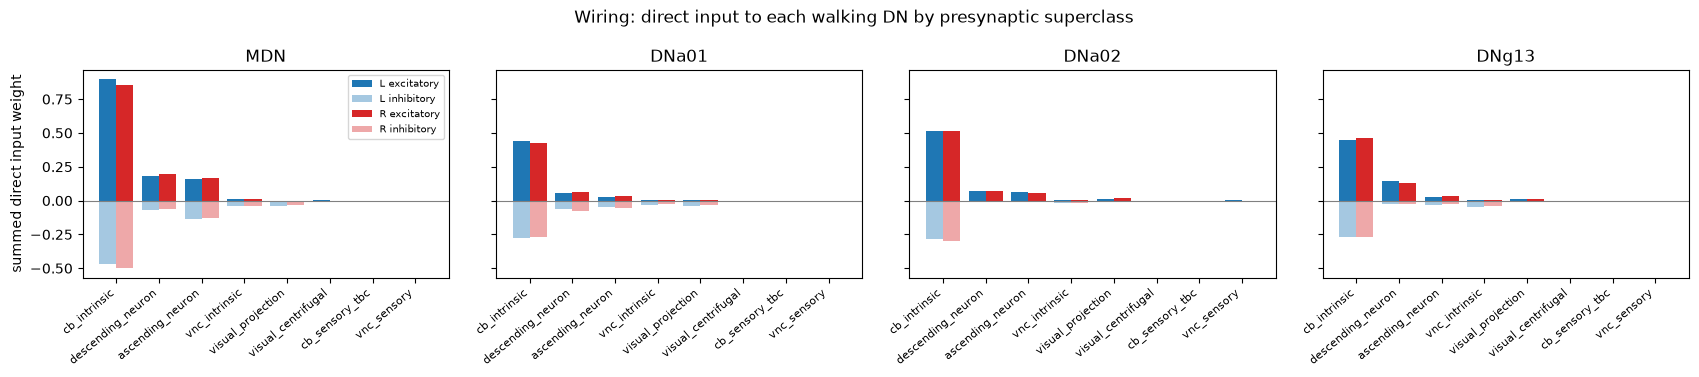

In [4]:
sups = sorted({k for v in superclass.values() for k in v}, key=lambda k: -sum(abs(v[k][0]) + abs(v[k][1]) for v in superclass.values() if k in v))[:8]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, t in zip(axes, TARGETS):
    x = np.arange(len(sups))
    for j, s in enumerate("LR"):
        exc = [superclass[(t, s)].get(k, [0, 0])[0] for k in sups]
        inh = [superclass[(t, s)].get(k, [0, 0])[1] for k in sups]
        ax.bar(x + (j - 0.5) * 0.4, exc, 0.4, color=["tab:blue", "tab:red"][j], label=f"{s} excitatory")
        ax.bar(x + (j - 0.5) * 0.4, inh, 0.4, color=["tab:blue", "tab:red"][j], alpha=0.4, label=f"{s} inhibitory")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(sups, rotation=40, ha="right", fontsize=8); ax.set_title(t)
axes[0].set_ylabel("summed direct input weight"); axes[0].legend(fontsize=7)
fig.suptitle("Wiring: direct input to each walking DN by presynaptic superclass")
fig.tight_layout(); fig.savefig(OUT / "wiring_superclass.png", dpi=110); plt.show()

## Candidates to stimulate

For each target group: the top excitatory and inhibitory direct input types and the strongest excitatory two-step-only
types (not already a direct input). Plus inputs the literature names: LC16 (drives MDN, Sen et al. 2017), PFL3 (direct
input to DNa02 but not DNa01, Rayshubskiy et al. 2025) and DNp09 (excites DNa02, Braun et al. 2024).
Each candidate is a (cell type, side) group; all its cells get the same injection.

In [5]:
cands = collections.OrderedDict()
for t in TARGETS:
    for s in "LR":
        d = sorted(direct[(t, s)].items(), key=lambda x: -x[1])
        for k, v in [x for x in d if x[1] > 0][:TOP_DIRECT]:
            cands.setdefault(k, set()).add(f"direct+ {t} {s}")
        for k, v in sorted([x for x in d if x[1] < 0], key=lambda x: x[1])[:TOP_INHIB]:
            cands.setdefault(k, set()).add(f"direct- {t} {s}")
        two = sorted(((k, v) for k, v in twostep[(t, s)].items() if k not in direct[(t, s)] and v > 0), key=lambda x: -x[1])
        for k, v in two[:TOP_TWO]:
            cands.setdefault(k, set()).add(f"two-step {t} {s}")
for k, why in [(("LC16", "L"), "literature MDN"), (("PFL3", "L"), "literature DNa02"), (("PFL3", "R"), "literature DNa02"),
               (("DNp09", "L"), "literature DNa02")]:
    cands.setdefault(k, set()).add(why)
cand_idx = {k: brain.cells([k[0]], side=k[1]) for k in cands}
cands = collections.OrderedDict((k, v) for k, v in cands.items() if len(cand_idx[k]))
rng = np.random.default_rng(0)
controls = {}
for k, idx in cand_idx.items():
    if k not in cands:
        continue
    pool = np.flatnonzero(sc == sc[idx[0]])
    pool = np.setdiff1d(pool, np.concatenate([idx, walking]))
    controls[k] = np.sort(rng.choice(pool, size=len(idx), replace=False))
print(len(cands), "candidates")
for k, why in cands.items():
    print(f"  {k[0]:16} {k[1]}  n={len(cand_idx[k]):3}  {sc[cand_idx[k][0]]:18} {'; '.join(sorted(why))}")

44 candidates
  DNpe023          R  n=  1  descending_neuron  direct+ MDN L; direct+ MDN R
  DNpe023          L  n=  1  descending_neuron  direct+ MDN L; direct+ MDN R
  LAL160,LAL161    R  n=  2  cb_intrinsic       direct+ MDN L
  CB0095           R  n=  1  cb_intrinsic       direct- MDN L
  LC9              R  n=115  visual_projection  two-step MDN L; two-step MDN R
  DNge127          L  n=  1  descending_neuron  two-step MDN L
  LAL171,LAL172    L  n=  2  cb_intrinsic       direct+ MDN R
  AN_multi_41      L  n=  1  ascending_neuron   direct- MDN R
  DNge127          R  n=  1  descending_neuron  two-step MDN R
  VES007           L  n=  1  cb_intrinsic       direct+ DNa01 L
  CB4105           R  n=  4  cb_intrinsic       direct+ DNa01 L
  VES074           R  n=  1  cb_intrinsic       direct+ DNa01 L
  LT51             L  n= 11  visual_projection  direct- DNa01 L
  LPC1             R  n=109  visual_projection  two-step DNa01 L
  LPLC4            R  n= 49  visual_projection  two-step D

## Simulation

One trial = reset with a seed, 0.2 s rest, then 1 s with `AMOUNT` volts injected every step into the stimulated cells.
Spike counts in the 1 s window give each walking DN's rate in each of 16 flies. `Δ = stimulated − baseline` fly by fly,
on the same seeds. A response counts as **up** or **down** when |z| > 3 (z = mean Δ / standard error over flies) and
|Δ| ≥ 1 Hz.

In [6]:
def trial(b, target_idx, amount, seed=0):
    b.reset(seed)
    for _ in range(WARM):
        b.step()
    counts = np.zeros((len(walking), BATCH), np.int32)
    slot = np.full(b.n, -1); slot[walking] = np.arange(len(walking))
    inject = [(target_idx, amount)] if target_idx is not None else []
    for _ in range(STEPS):
        for k, f in enumerate(b.step(inject=inject)):
            s = slot[f]; counts[s[s >= 0], k] += 1
    return counts / (STEPS * b.dt)            # Hz, (walking cells, flies)

pos = {c: i for i, c in enumerate(walking)}
def dn_delta(rates, base):
    out = {}
    for t in READ:
        for s in "LR":
            rows_ = [pos[c] for c in group(t, s)]
            d = (rates[rows_] - base[rows_]).mean(axis=0)
            out[(t, s)] = (float(d.mean()), float(d.std(ddof=1)), float(d.mean() / (d.std(ddof=1) / np.sqrt(len(d)) + 1e-9)),
                           float(base[rows_].mean()))
    return out

t0 = time.time()
base = trial(brain, None, 0.0)
print("baseline (Hz): " + ", ".join(f"{t} {s} {base[[pos[c] for c in group(t, s)]].mean():.2f}" for t in READ for s in "LR"))
sim, ctl = {}, {}
for i, k in enumerate(cands):
    sim[k] = dn_delta(trial(brain, cand_idx[k], AMOUNT), base)
    ctl[k] = dn_delta(trial(brain, controls[k], AMOUNT), base)
print(f"{2 * len(cands) + 1} conditions in {time.time() - t0:.0f} s")

baseline (Hz): MDN L 0.19, MDN R 0.44, DNa01 L 0.56, DNa01 R 0.56, DNa02 L 0.56, DNa02 R 0.19, DNg13 L 0.50, DNg13 R 1.38, DNg100 L 0.12, DNg100 R 0.06, DNp09 L 0.69, DNp09 R 0.62, DNb05 L 17.69, DNb05 R 21.19, DNb06 L 0.50, DNb06 R 0.31


89 conditions in 441 s


In [7]:
def call(d, sd_, z):
    return "up" if (z > 3 and d >= 1) else "down" if (z < -3 and d <= -1) else "none"

out_rows = []
for k in cands:
    for which, res, idx in [("candidate", sim[k], cand_idx[k]), ("random control", ctl[k], controls[k])]:
        for (t, s), (d, sdv, z, b0) in res.items():
            wd = float(W[group(t, s)][:, idx].sum())
            out_rows.append(dict(stimulus=f"{k[0]} {k[1]}", n_cells=len(idx), set=which, why="; ".join(sorted(cands[k])),
                                 readout=t, side=s, base_hz=round(b0, 2), delta_hz=round(d, 2), sd_hz=round(sdv, 2),
                                 z=round(z, 1), call=call(d, sdv, z), direct_weight=round(wd, 5)))
with open(OUT / "simulated_responses.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(out_rows[0])); w.writeheader(); w.writerows(out_rows)

print("simulated responses of the four target types (Δ Hz, * = called up/down):")
hdr = "".join(f"{t + ' ' + s:>10}" for t in TARGETS for s in "LR")
print(f"{'stimulus':24}{'set':>8}{hdr}")
for k in cands:
    for which, res in [("cand", sim[k]), ("ctrl", ctl[k])]:
        cells = "".join(f"{res[(t, s)][0]:+9.2f}{'*' if call(res[(t, s)][0], res[(t, s)][1], res[(t, s)][2]) != 'none' else ' '}"
                        for t in TARGETS for s in "LR")
        print(f"{k[0][:16] + ' ' + k[1]:24}{which:>8}{cells}")

simulated responses of the four target types (Δ Hz, * = called up/down):
stimulus                     set     MDN L     MDN R   DNa01 L   DNa01 R   DNa02 L   DNa02 R   DNg13 L   DNg13 R
DNpe023 R                   cand    +3.31*    +1.94*    +0.12     +0.00     +0.00     +0.06     -0.31     -0.12 
DNpe023 R                   ctrl    -0.06     -0.09     -0.06     +0.06     +0.06     -0.06     -0.06     -0.12 
DNpe023 L                   cand    +1.34*    +3.84*    -0.06     -0.12     +0.38     -0.12     +0.06     -0.75 
DNpe023 L                   ctrl    -0.03     +0.03     +0.12     -0.12     +0.00     -0.06     +0.19     -0.12 
LAL160,LAL161 R             cand    +1.00*    +0.44     +0.94     +0.00     +0.12     +0.06     +0.31     -0.31 
LAL160,LAL161 R             ctrl    -0.06     +0.03     -0.06     -0.06     +0.12     -0.06     +0.12     -0.19 
CB0095 R                    cand    -0.19     -0.28     -0.06     +0.12     +0.19     +0.00     +0.06     -0.12 
CB0095 R               

## Plots (simulated)

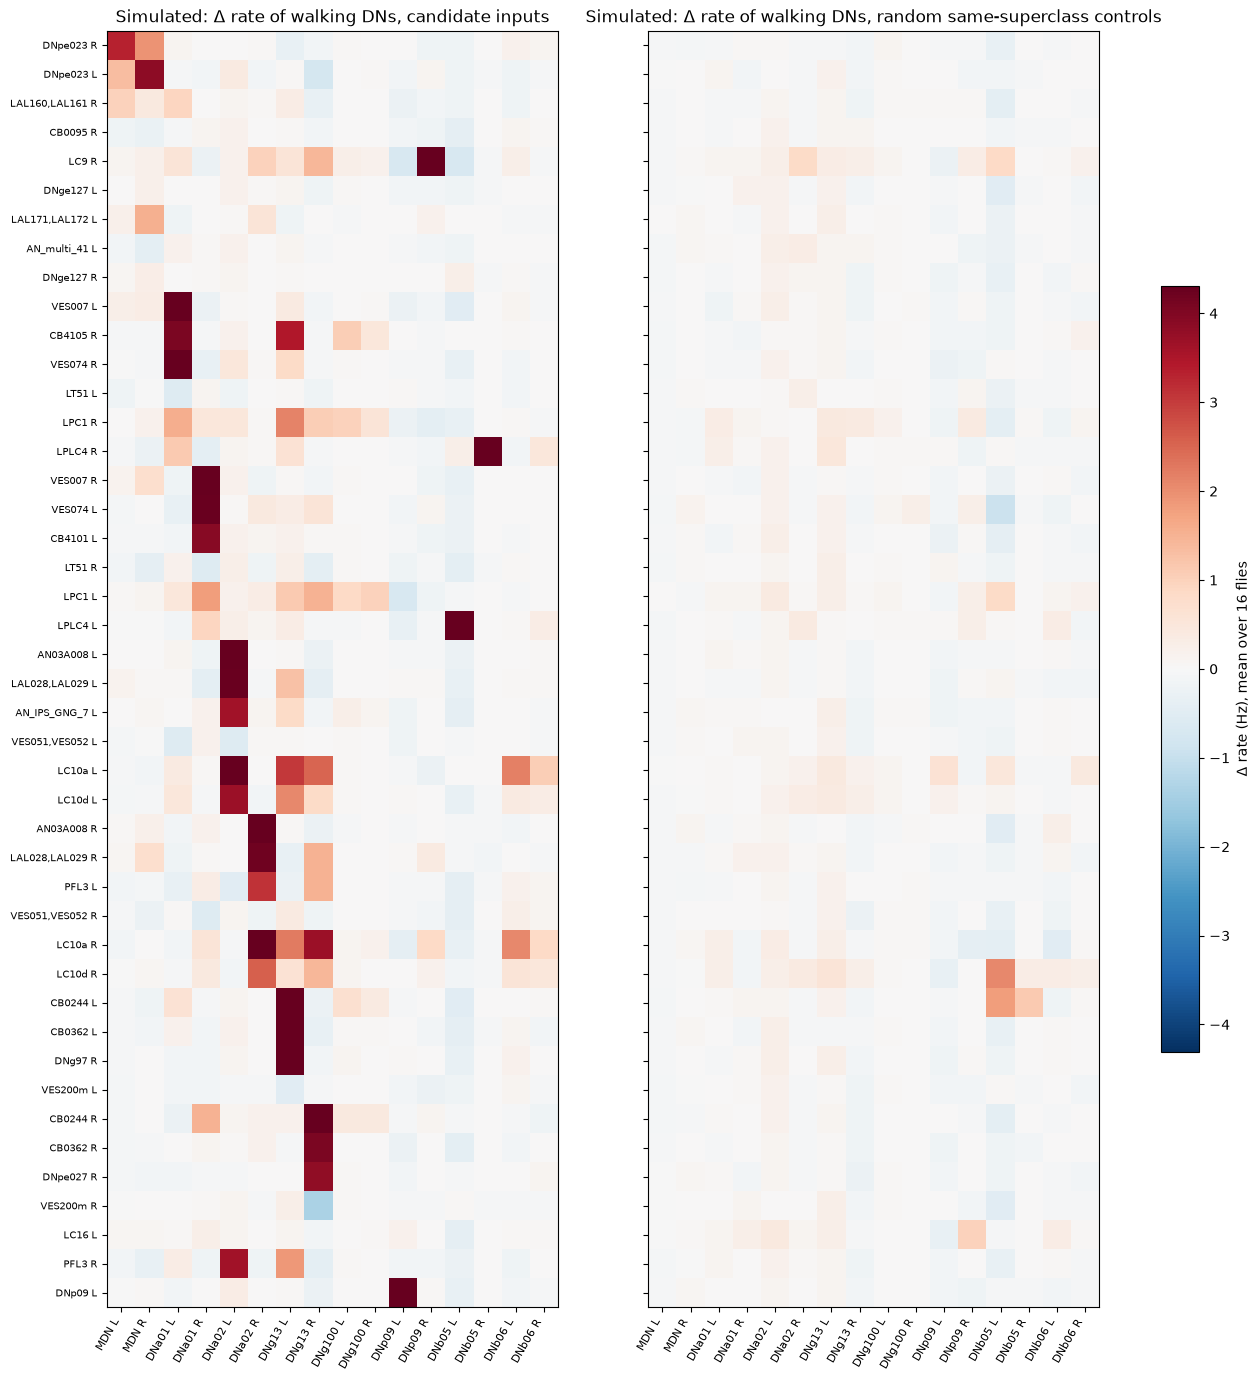

In [8]:
labels = [f"{k[0]} {k[1]}" for k in cands]
cols = [(t, s) for t in READ for s in "LR"]
M = np.array([[sim[k][c][0] for c in cols] for k in cands])
Mc = np.array([[ctl[k][c][0] for c in cols] for k in cands])
lim = np.percentile(np.abs(M), 98)
fig, axes = plt.subplots(1, 2, figsize=(16, 0.32 * len(cands) + 2.5), sharey=True)
for ax, data, title in [(axes[0], M, "candidate inputs"), (axes[1], Mc, "random same-superclass controls")]:
    im = ax.imshow(data, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([f"{t} {s}" for t, s in cols], rotation=60, ha="right", fontsize=8)
    ax.set_title(f"Simulated: Δ rate of walking DNs, {title}")
axes[0].set_yticks(range(len(labels))); axes[0].set_yticklabels(labels, fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.6, label="Δ rate (Hz), mean over 16 flies")
fig.savefig(OUT / "responses_heatmap.png", dpi=110, bbox_inches="tight"); plt.show()

## Wiring vs simulation

For every (candidate, target type, side) pair: the summed direct weight from the stimulated cells onto that DN (wiring)
against the simulated Δ rate. Points far from the trend are effects the direct wiring does not predict (multi-step
paths, inhibition through other cells, or saturation).

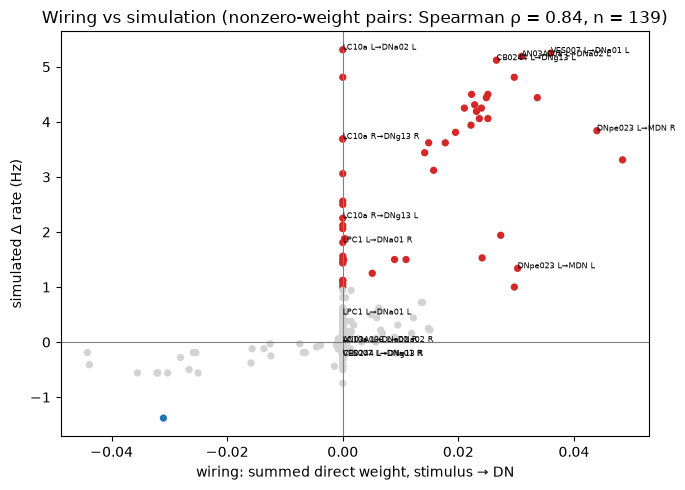

Spearman ρ, all 352 pairs: 0.50 (213 have zero direct weight); nonzero-weight pairs only: 0.84 (n = 139). Pairs share candidates and readouts, so no p-value is given.
predicted by direct wiring (|w| > 0.005) vs simulated call:
  wiring up   : sim up 29, sim down 0, sim none 16
  wiring down : sim up 0, sim down 1, sim none 19
  wiring none : sim up 21, sim down 0, sim none 266

called with no direct synapse above |w| = 0.005: 21 (19 with zero direct weight)
not predicted by direct wiring but simulated (|Δ| largest):
  LC10a L              → DNa02 L: Δ +5.31 Hz (direct +0.0000)
  LC10a R              → DNa02 R: Δ +4.81 Hz (direct +0.0000)
  LC10d L              → DNa02 L: Δ +3.69 Hz (direct +0.0000)
  LC10a R              → DNg13 R: Δ +3.69 Hz (direct +0.0000)
  LC10a L              → DNg13 L: Δ +3.06 Hz (direct +0.0000)
  LC10d R              → DNa02 R: Δ +2.56 Hz (direct +0.0000)
  LC10a L              → DNg13 R: Δ +2.50 Hz (direct +0.0000)
  LC10a R              → DNg13 L: Δ +2.25 Hz

In [9]:
pairs = [r for r in out_rows if r["set"] == "candidate" and r["readout"] in TARGETS]
x = np.array([r["direct_weight"] for r in pairs]); y = np.array([r["delta_hz"] for r in pairs])
rho, p = spearmanr(x, y)
nzm = x != 0
rho_nz, p_nz = spearmanr(x[nzm], y[nzm])
best = {}
for r in pairs:   # label only the strongest response of each target type, and the largest response with no direct wiring
    key = (r["readout"], abs(r["direct_weight"]) > 0)
    if r["call"] != "none" and (key not in best or r["delta_hz"] > best[key]["delta_hz"]):
        best[key] = r
LABEL = {(r["stimulus"], r["readout"]) for r in best.values()}
fig, ax = plt.subplots(figsize=(7, 5))
colors = {"up": "tab:red", "down": "tab:blue", "none": "lightgrey"}
ax.scatter(x, y, c=[colors[r["call"]] for r in pairs], s=18)
for r in pairs:
    if (r["stimulus"], r["readout"]) in LABEL:
        ax.annotate(f"{r['stimulus']}→{r['readout']} {r['side']}", (r["direct_weight"], r["delta_hz"]), fontsize=6)
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("wiring: summed direct weight, stimulus → DN"); ax.set_ylabel("simulated Δ rate (Hz)")
ax.set_title(f"Wiring vs simulation (nonzero-weight pairs: Spearman ρ = {rho_nz:.2f}, n = {int(nzm.sum())})")
fig.tight_layout(); fig.savefig(OUT / "wiring_vs_sim.png", dpi=110); plt.show()

def agree(r):
    w = r["direct_weight"]
    pred = "up" if w > 0.005 else "down" if w < -0.005 else "none"
    return pred, r["call"]
tab = collections.Counter(agree(r) for r in pairs)
print(f"Spearman ρ, all {len(pairs)} pairs: {rho:.2f} ({int((x == 0).sum())} have zero direct weight); "
      f"nonzero-weight pairs only: {rho_nz:.2f} (n = {int(nzm.sum())}). Pairs share candidates and readouts, so no p-value is given.")
print("predicted by direct wiring (|w| > 0.005) vs simulated call:")
for pr in ["up", "down", "none"]:
    print(f"  wiring {pr:5}: " + ", ".join(f"sim {c} {tab[(pr, c)]}" for c in ["up", "down", "none"]))
nd = [r for r in pairs if agree(r)[0] == "none" and r["call"] != "none"]
print(f"\ncalled with no direct synapse above |w| = 0.005: {len(nd)} ({sum(r['direct_weight'] == 0 for r in nd)} with zero direct weight)")
print("not predicted by direct wiring but simulated (|Δ| largest):")
for r in sorted([r for r in pairs if agree(r)[0] == "none" and r["call"] != "none"], key=lambda r: -abs(r["delta_hz"]))[:8]:
    print(f"  {r['stimulus']:20} → {r['readout']} {r['side']}: Δ {r['delta_hz']:+.2f} Hz (direct {r['direct_weight']:+.4f})")
print("\npredicted by direct wiring but no simulated effect:")
for r in sorted([r for r in pairs if agree(r)[0] != "none" and r["call"] == "none"], key=lambda r: -abs(r["direct_weight"]))[:8]:
    print(f"  {r['stimulus']:20} → {r['readout']} {r['side']}: direct {r['direct_weight']:+.4f}, Δ {r['delta_hz']:+.2f} Hz")
ctl_pairs = [r for r in out_rows if r["set"] == "random control" and r["readout"] in TARGETS]
print(f"\ncalled responses: candidates {sum(r['call'] != 'none' for r in pairs)}/{len(pairs)}, "
      f"random controls {sum(r['call'] != 'none' for r in ctl_pairs)}/{len(ctl_pairs)} (the four target types)")
all_c = [r for r in out_rows if r["set"] == "candidate"]; all_k = [r for r in out_rows if r["set"] == "random control"]
print(f"all {len(READ) * 2} readout groups: candidates {sum(r['call'] != 'none' for r in all_c)}/{len(all_c)}, "
      f"random controls {sum(r['call'] != 'none' for r in all_k)}/{len(all_k)}")
for r in all_k:
    if r["call"] != "none":
        print(f"  control call: {r['stimulus']} ctrl → {r['readout']} {r['side']}: Δ {r['delta_hz']:+.2f} Hz (z {r['z']})")

## Inhibitory inputs need an active target (simulated)

The walking DNs fire below 1.5 Hz at rest, so an inhibitory input has little to remove: that is why the direct
inhibitory inputs above show no called response. Here each target group is first driven by its excitatory candidate
with the largest direct weight onto it, and the inhibitory candidate is added on top, on the same seeds. Control: the
same driver plus the inhibitor's random same-superclass set of the same size (the one used above), so the drop is
compared with what adding that many extra cells firing at 50 Hz does anyway.

In [10]:
inh_rows = []
for k, why in cands.items():
    for tag in [w for w in why if w.startswith("direct- ")]:
        _, t, s = tag.split()
        drvs = [d for d, w in cands.items() if f"direct+ {t} {s}" in w]
        if not drvs:
            continue
        rows_ = [pos[c] for c in group(t, s)]
        drv = max(drvs, key=lambda d: float(W[group(t, s)][:, cand_idx[d]].sum()))
        r_drv = trial(brain, cand_idx[drv], AMOUNT)
        both = np.unique(np.concatenate([cand_idx[drv], cand_idx[k]]))
        r_both = trial(brain, both, AMOUNT)
        r_ctl = trial(brain, np.unique(np.concatenate([cand_idx[drv], controls[k]])), AMOUNT)
        d = (r_both[rows_] - r_drv[rows_]).mean(axis=0)
        z = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)) + 1e-9)
        dc = (r_both[rows_] - r_ctl[rows_]).mean(axis=0)
        zc = dc.mean() / (dc.std(ddof=1) / np.sqrt(len(dc)) + 1e-9)
        inh_rows.append(dict(inhibitor=f"{k[0]} {k[1]}", target=f"{t} {s}", driver=f"{drv[0]} {drv[1]}",
                             driven_hz=round(float(r_drv[rows_].mean()), 2), driven_plus_inhibitor_hz=round(float(r_both[rows_].mean()), 2),
                             driven_plus_control_hz=round(float(r_ctl[rows_].mean()), 2), n_inhibitor_cells=len(cand_idx[k]),
                             delta_hz=round(float(d.mean()), 2), z=round(float(z), 1),
                             delta_vs_control_hz=round(float(dc.mean()), 2), z_vs_control=round(float(zc), 1),
                             direct_weight=round(float(W[group(t, s)][:, cand_idx[k]].sum()), 4)))
with open(OUT / "inhibition_test.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(inh_rows[0])); w.writeheader(); w.writerows(inh_rows)
for r in inh_rows:
    print(f"{r['inhibitor']:18} → {r['target']:8} (driven by {r['driver']:16}): {r['driven_hz']:5.2f} → {r['driven_plus_inhibitor_hz']:5.2f} Hz "
          f"(Δ {r['delta_hz']:+.2f}, z {r['z']:.1f}); driver + {r['n_inhibitor_cells']} random cells {r['driven_plus_control_hz']:5.2f} Hz "
          f"(inhibitor vs control Δ {r['delta_vs_control_hz']:+.2f}, z {r['z_vs_control']:.1f}); direct {r['direct_weight']:+.4f}")

CB0095 R           → MDN L    (driven by DNpe023 R       ):  3.50 →  0.31 Hz (Δ -3.19, z -23.4); driver + 1 random cells  3.72 Hz (inhibitor vs control Δ -3.41, z -23.3); direct -0.0442
AN_multi_41 L      → MDN R    (driven by DNpe023 L       ):  4.28 →  0.44 Hz (Δ -3.84, z -30.3); driver + 1 random cells  4.34 Hz (inhibitor vs control Δ -3.91, z -25.6); direct -0.0438
LT51 L             → DNa01 L  (driven by VES007 L        ):  5.81 →  0.50 Hz (Δ -5.31, z -35.3); driver + 11 random cells  5.75 Hz (inhibitor vs control Δ -5.25, z -36.4); direct -0.0355
LT51 R             → DNa01 R  (driven by VES007 R        ):  5.00 →  0.25 Hz (Δ -4.75, z -42.5); driver + 11 random cells  4.88 Hz (inhibitor vs control Δ -4.62, z -29.9); direct -0.0320
VES051,VES052 L    → DNa02 L  (driven by AN03A008 L      ):  5.75 →  0.75 Hz (Δ -5.00, z -27.4); driver + 4 random cells  5.81 Hz (inhibitor vs control Δ -5.06, z -26.2); direct -0.0250
VES051,VES052 R    → DNa02 R  (driven by AN03A008 R      ):  5.00 → 

## Literature checks

| claim in the literature | source | what to look at here |
|---|---|---|
| MDN activity is necessary and sufficient for backward walking | Bidaye et al., *Science* 2014 | MDN = `backward_*` group |
| LC16 visual projection neurons drive MDN (looming → backward walking and turning) | Sen et al., *Curr Biol* 2017 | LC16 → MDN wiring and simulation |
| MooSEZ neurons in the SEZ drive backward locomotion partly through MDN | Israel et al., *Curr Biol* 2022 | not tested: no MaleCNS name mapping checked |
| DNa01 and DNa02 inputs are largely non-overlapping; only DNa02 gets direct PFL3 input | Rayshubskiy et al., *eLife* 2025 | overlap of top inputs; PFL3 → DNa02 vs DNa01 |
| DNa02 and DNg13 receive distinct input and can be recruited differently | Yang et al., *Cell* 2024 | overlap of top inputs; simulated responses |
| DNp09 (forward walking) directly excites DNa02 | Braun et al., *Nature* 2024 | DNp09 → DNa02 wiring and simulation |

In [11]:
def top_set(t, s, n=20):
    return {k for k, v in sorted(direct[(t, s)].items(), key=lambda x: -abs(x[1]))[:n]}
def jaccard(a, b):
    return len(a & b) / len(a | b)
for s in "LR":
    print(f"side {s}: top-20 direct input types shared, Jaccard  DNa01/DNa02 {jaccard(top_set('DNa01', s), top_set('DNa02', s)):.2f}, "
          f"DNa02/DNg13 {jaccard(top_set('DNa02', s), top_set('DNg13', s)):.2f}, MDN/DNa02 {jaccard(top_set('MDN', s), top_set('DNa02', s)):.2f}")
def called(t):
    return {r["stimulus"] for r in out_rows if r["set"] == "candidate" and r["readout"] == t and r["call"] != "none"}
for a, b in [("DNa01", "DNa02"), ("DNa02", "DNg13")]:
    sh = called(a) & called(b)
    print(f"simulated: candidates called on {a} {len(called(a))}, on {b} {len(called(b))}, on both {len(sh)}: {', '.join(sorted(sh)) or '-'}")
for pre in ["LC16", "PFL3", "DNp09"]:
    for t in TARGETS:
        vals = []
        for s in "LR":
            post = group(t, s)
            w1 = np.asarray(W[post].sum(axis=0)).ravel()
            pi = brain.cells([pre])
            vals.append(f"{s}: direct {float(w1[pi].sum()):+.4f}, two-step {float((sparse.csr_matrix(w1) @ W[:, pi]).sum()):+.5f}")
        print(f"wiring {pre:5} → {t:5}  " + " | ".join(vals))
for k in [("LC16", "L"), ("PFL3", "L"), ("PFL3", "R"), ("DNp09", "L")]:
    if k in sim:
        print(f"simulated {k[0]} {k[1]}: " + ", ".join(f"{t} {s} {sim[k][(t, s)][0]:+.2f} (z {sim[k][(t, s)][2]:.1f})" for t in TARGETS for s in "LR"))

side L: top-20 direct input types shared, Jaccard  DNa01/DNa02 0.03, DNa02/DNg13 0.03, MDN/DNa02 0.00
side R: top-20 direct input types shared, Jaccard  DNa01/DNa02 0.03, DNa02/DNg13 0.00, MDN/DNa02 0.03
simulated: candidates called on DNa01 10, on DNa02 12, on both 0: -
simulated: candidates called on DNa02 12, on DNg13 19, on both 9: LAL028,LAL029 L, LAL028,LAL029 R, LC10a L, LC10a R, LC10d L, LC10d R, LC9 R, PFL3 L, PFL3 R
wiring LC16  → MDN    L: direct +0.0000, two-step +0.00010 | R: direct +0.0000, two-step +0.00009


wiring LC16  → DNa01  L: direct +0.0000, two-step -0.00013 | R: direct +0.0000, two-step -0.00006
wiring LC16  → DNa02  L: direct +0.0000, two-step +0.00013 | R: direct +0.0000, two-step +0.00019


wiring LC16  → DNg13  L: direct +0.0000, two-step +0.00020 | R: direct +0.0000, two-step +0.00015
wiring PFL3  → MDN    L: direct +0.0000, two-step -0.00299 | R: direct +0.0000, two-step -0.00277


wiring PFL3  → DNa01  L: direct +0.0000, two-step +0.00039 | R: direct +0.0000, two-step +0.00013
wiring PFL3  → DNa02  L: direct +0.0149, two-step -0.00147 | R: direct +0.0157, two-step -0.00190


wiring PFL3  → DNg13  L: direct +0.0003, two-step +0.00076 | R: direct +0.0002, two-step +0.00097
wiring DNp09 → MDN    L: direct +0.0006, two-step -0.00021 | R: direct +0.0006, two-step -0.00047


wiring DNp09 → DNa01  L: direct +0.0000, two-step -0.00010 | R: direct +0.0002, two-step -0.00019
wiring DNp09 → DNa02  L: direct +0.0019, two-step +0.00021 | R: direct +0.0004, two-step -0.00001


wiring DNp09 → DNg13  L: direct +0.0000, two-step +0.00006 | R: direct +0.0005, two-step -0.00008
simulated LC16 L: MDN L +0.09 (z 1.4), MDN R +0.09 (z 1.9), DNa01 L +0.06 (z 0.4), DNa01 R +0.25 (z 1.7), DNa02 L +0.12 (z 1.0), DNa02 R +0.00 (z 0.0), DNg13 L +0.12 (z 1.0), DNg13 R -0.12 (z -0.6)
simulated PFL3 L: MDN L -0.12 (z -1.7), MDN R -0.09 (z -1.9), DNa01 L -0.31 (z -2.6), DNa01 R +0.31 (z 1.6), DNa02 L -0.50 (z -3.9), DNa02 R +3.12 (z 20.2), DNg13 L -0.25 (z -2.2), DNg13 R +1.50 (z 11.6)
simulated PFL3 R: MDN L -0.12 (z -1.7), MDN R -0.31 (z -5.0), DNa01 L +0.31 (z 1.8), DNa01 R -0.19 (z -1.0), DNa02 L +3.62 (z 29.0), DNa02 R -0.19 (z -1.9), DNg13 L +1.88 (z 8.5), DNg13 R -0.44 (z -2.8)
simulated DNp09 L: MDN L -0.03 (z -0.6), MDN R +0.06 (z 0.7), DNa01 L -0.12 (z -1.5), DNa01 R +0.00 (z 0.0), DNa02 L +0.31 (z 2.6), DNa02 R +0.00 (z 0.0), DNg13 L +0.06 (z 1.0), DNg13 R -0.25 (z -1.7)


## Results

All numbers are from the run saved in this notebook (MaleCNS v1.0, flybrain 0.1.1, CPU, 16 flies per condition).

**Wiring.** The four walking DN types get almost entirely separate inputs: of the top 20 direct input types, DNa01 and
DNa02 share one (Jaccard 0.03 on each side), DNa02 and DNg13 at most one, MDN and DNa02 at most one. Most input is
from central-brain intrinsic neurons, with both excitation and inhibition. Strongest direct excitatory inputs:
MDN ← DNpe023 (both sides), DNa01 ← VES007 / VES074 / CB4105, DNa02 ← AN03A008 / LAL028,LAL029 / AN_IPS_GNG_7,
DNg13 ← CB0244 / CB0362. The strongest two-step inputs to DNa02 and DNg13 are the LC10 visual projection neurons
(LC10a, LC10d, LC10c); to DNa01, LPC1 and LPLC4.

**Simulation.** 44 candidate inputs stimulated one at a time: 51 of 352 (candidate, target DN) pairs gave a called
response (|z| > 3, |Δ| ≥ 1 Hz); the same-size random controls gave 0 of 352. Across all 16 readout groups (the four
targets plus DNg100, DNp09, DNb05, DNb06) candidates gave 61 of 704 calls and controls 4 of 704 (LC10d R ctrl → DNb05 L,
CB0244 L ctrl → DNb05 L and R, LC16 L ctrl → DNp09 R), so the control rate is low but not zero.

* Direct excitatory inputs drive their target selectively, by +1 to +5 Hz from a resting rate below 1.5 Hz
  (29 of 45 pairs with direct weight > 0.005 were called up, none down).
* Direct inhibitory inputs show nothing at rest (1 of 20 called), because the DNs are near zero. With the target first
  driven by the excitatory candidate with the largest direct weight onto it, all 8 tested inhibitory inputs silenced it
  (Δ −3.2 to −5.4 Hz, |z| ≥ 23): e.g. LT51 L cut DNa01 L from 5.81 to 0.50 Hz, VES051,VES052 R cut DNa02 R from 5.00 to
  0.12 Hz, CB0095 R cut MDN L from 3.50 to 0.31 Hz. Adding a random same-superclass set of the same size to the driver
  instead left the target at 3.72 to 6.00 Hz (within 0.13 Hz of the driver alone), so the drop is specific to the
  inhibitor, not an effect of forcing extra cells to fire.
* 21 called responses had no direct synapse above |w| = 0.005 (19 with zero direct weight), the largest LC10a L → DNa02 L (+5.31 Hz) and LC10a → DNg13 on
  both sides (+2.25 to +3.69 Hz): two-step visual paths the direct wiring alone misses.
* On the 139 pairs with nonzero direct weight, wiring and simulated Δ agree in rank (Spearman ρ = 0.84). Over all 352
  pairs ρ is 0.50, but 213 of those have zero direct weight, and the pairs are not independent (44 candidates × 8
  readouts), so no p-value is given.

**Against the literature.**

* *Reproduces:* PFL3 → DNa02 but not DNa01 (Rayshubskiy et al. 2025). Wiring: PFL3 → DNa02 direct weight 0.015 per
  side, → DNa01 zero. Simulated: PFL3 L raised DNa02 R by +3.12 Hz (z 20) and PFL3 R raised DNa02 L by +3.62 Hz
  (z 29), with DNa01 unchanged (|Δ| ≤ 0.31 Hz). The crossed pattern follows the side label, which is the soma side.
* *Reproduces:* DNa01 and DNa02 have distinct inputs (Rayshubskiy et al. 2025), by wiring and in simulation: top-20
  Jaccard 0.03 per side, and none of the 10 candidates called on DNa01 is called on DNa02 (12).
* *Partly reproduces:* DNa02 and DNg13 (Yang et al. 2024) are **distinct by wiring, largely shared in simulation**.
  Their top-20 direct inputs barely overlap (Jaccard 0.03 left, 0.00 right), but 9 of the 12 candidates called on
  DNa02 are also called on DNg13 (LC9 R, LAL028,LAL029 L/R, LC10a L/R, LC10d L/R, PFL3 L/R). For example LC10a L gives
  DNa02 L +5.31 Hz (z 30) and DNg13 L / R +3.06 / +2.50 Hz (z 18 / 12).
* *Does not reproduce:* LC16 → MDN (Sen et al. 2017). MaleCNS has no direct LC16 → MDN synapses and only a very weak
  two-step path (≈ 1e-4); stimulating all 88 left LC16 cells moved MDN by +0.09 Hz (z < 2). The published effect may
  run through longer paths, or through the VNC, which this model doesn't have.
* *Weak:* DNp09 → DNa02 (Braun et al. 2024): direct weight 0.0019 on the left, simulated +0.31 Hz (z 2.6), below
  the call threshold.
* MooSEZ (Israel et al. 2022) was not tested: its MaleCNS cell types were not identified here.


## What the model leaves out

* **Input is voltage injection** into whole cell types at a fixed strength (every stimulated cell fires every step), not
  a natural stimulus. Weaker or patterned drive could change which DNs follow.
* **Brain only.** There is no VNC or leg model, so "walking" is read from DN firing, not from movement; MDN's
  backward-walking effect lives in the VNC (Feng et al., *Nat Commun* 2020).
* **One wiring diagram**, fixed hand-calibrated parameters (nothing tuned here), chemical synapses only.
* **Candidates come from the top of the wiring ranking**, so the comparison favours inputs the wiring already predicts;
  a full screen of every input type was not run.
* **Random controls** are one draw per candidate (seed 0), same superclass and size.
* **Sensory feedback is on** (`sensory_input=True`, flybrain's default): synapses onto sensory neurons are kept, so
  the olfactory receptor neuron loop runs near its maximum rate at rest and feeds every condition, stimulated and
  baseline alike. `sensory_input=False` would drop those synapses; it was not run here.